# Q-Q Plot (Quantile-Quantile)

**Family:** Distribution &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Distribution:* Show values in a dataset and how often they occur; the shape (skew, spread, gaps) is the story.

## Design purpose

Plots a sample's quantiles against those of a theoretical distribution, usually the normal. If the points follow the diagonal, the data fits; curved tails show skew or heavy tails.

## When to use

- Check the normality assumption before t-tests or regression (e.g. on residuals)
- Diagnose skew, heavy tails or outliers relative to a reference distribution
- Compare two samples' distributions quantile by quantile

## Avoid when

- Communicating with a general audience (it is a diagnostic tool)

## Alternatives

- Histogram with a fitted normal curve
- ECDF vs. theoretical CDF

## Example

Normal vs. right-skewed vs. heavy-tailed samples (n = 200 each), side by side.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
from scipy import stats
rng = np.random.default_rng(43)
samples = {
    "Normal": rng.normal(0, 1, 200),
    "Right-skewed (lognormal)": rng.lognormal(0, 0.6, 200),
    "Heavy-tailed (t, df=3)": rng.standard_t(3, 200),
}
{k: round(stats.skew(v), 2) for k, v in samples.items()}

{'Normal': np.float64(-0.03),
 'Right-skewed (lognormal)': np.float64(1.58),
 'Heavy-tailed (t, df=3)': np.float64(2.1)}

### Plot

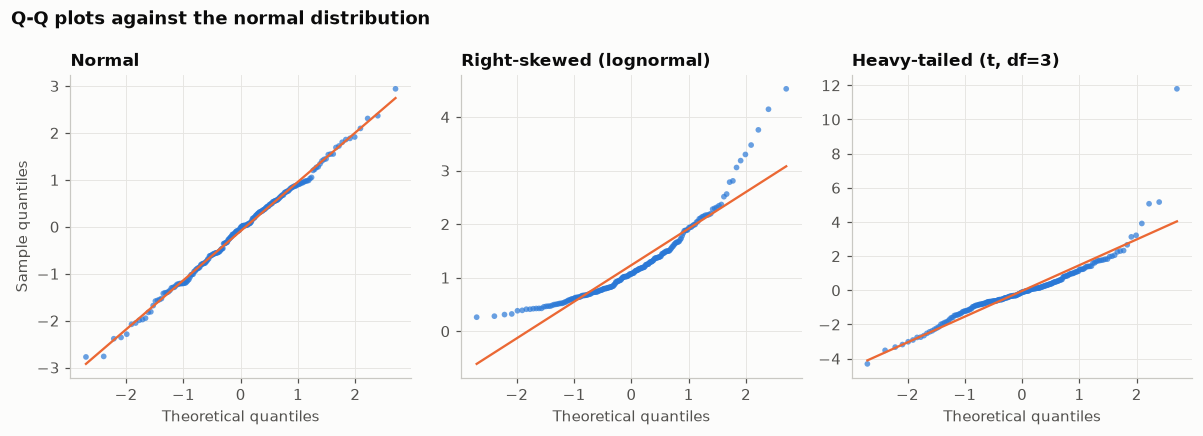

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, (name, x) in zip(axes, samples.items()):
    (osm, osr), (slope, intercept, r) = stats.probplot(x, dist="norm")
    ax.scatter(osm, osr, s=14, color=PALETTE[0], alpha=0.7, edgecolor="none")
    ax.plot(osm, slope * osm + intercept, color=PALETTE[1], linewidth=1.5)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("Theoretical quantiles")
axes[0].set_ylabel("Sample quantiles")
fig.suptitle("Q-Q plots against the normal distribution", x=0.01, ha="left", weight="bold")
fig.tight_layout()
plt.show()

## How to read it

Points on the orange line mean the data matches a normal distribution. An upward curve at the right end means right skew, and an S-shape with both ends pulling away means heavy tails.

---
Standalone script: [`qq_plot.py`](qq_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)